# Evaluation of Deep Learning Models

This notebook evaluates trained multi-class segmentation models specifically inside a **boundary zone of interest** (e.g., within 10 pixels of the water/land boundary). The approach directly follows `evaluate_pixel_based_metrics.ipynb` for fair comparison.

## Evaluation Strategy

- For each patch patch in the test dataset
- Predict the multi-class mask using the DL model 
- Collapse GT multi-class to binary water/no-water (with ignore mask)
- Collapse Prediction to binary water/no-water
- Calculate IoU and Dice metrics excluding ignore pixels and constrained to the boundary zone
- Aggregate results into a DataFrame for analysis

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# Add project root to sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Import utility functions from evaluation_utils
from notebooks.utils.evaluation_utils import (
    collapse_gt_to_binary, 
    create_boundary_zone_mask, 
    calculate_metrics
)

# Import Deep Learning utilities
from src.dl_models import get_model, CoastlineDataset

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Libraries imported successfully!")

/opt/anaconda3/envs/s2_benchmark/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully!


## Configuration

Define paths, models, class mappings, boundary zone parameters and load datasets.

**Note:** PyTorch `CoastlineDataset` subtracts 1 from all classes mapping values from 1-5 to 0-4 (with 255 as ignore_index):
* Original 3 & 5 $\rightarrow$ Mapped 2 & 4 (Water classes)
* Original 2 & 4 $\rightarrow$ Mapped 1 & 3 (No-water / land classes)
* Original 1 & 255 $\rightarrow$ Mapped 0 & 255 (Ignored classes)

In [2]:
# Target Study Areas and General setup
STUDY_NAMES = ["puntal", "salinas"]

# Base directories
BASE_DIR = Path("..") / "data"
TEST_NPY_DIR = BASE_DIR / "dl_npy" / "test"
MODELS_DIR = Path("..") / "results" / "models"

# Available Models to Evaluate
EVAL_MODELS = [
    {
        "name": "unet_resnet34",
        "arch": "unet",
        "encoder": "resnet34",
        "filepath": MODELS_DIR / "best_model_unet_resnet34_best_run.pth"
    },
    {
        "name": "unet_efficientnet-b4",
        "arch": "unet",
        "encoder": "efficientnet-b4",
        "filepath": MODELS_DIR / "best_model_unet_efficientnet-b4_best_run.pth"
    },
    {
        "name": "deeplabv3plus_resnet34",
        "arch": "deeplabv3plus",
        "encoder": "resnet34",
        "filepath": MODELS_DIR / "best_model_deeplabv3plus_resnet34_best_run.pth"
    },
    {
        "name": "deeplabv3plus_efficientnet-b4",
        "arch": "deeplabv3plus",
        "encoder": "efficientnet-b4",
        "filepath": MODELS_DIR / "best_model_deeplabv3plus_efficientnet-b4_best_run.pth"
    },
    {
        "name": "segformer_mit_b1",
        "arch": "segformer",
        "encoder": "mit_b1",
        "filepath": MODELS_DIR / "best_model_segformer_mit_b1_best_run.pth"
    },
    {
        "name": "segformer_mit_b2",
        "arch": "segformer",
        "encoder": "mit_b2",
        "filepath": MODELS_DIR / "best_model_segformer_mit_b2_best_run.pth"
    }
]

# Inference parameters
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
BATCH_SIZE = 1 # Keep 1 for patch-level inference tracking

# Boundary zone evaluation parameters
BOUNDARY_OFFSET_PIXELS = 10  # Symmetric offset around water/land boundary
MIN_BOUNDARY_PIXELS = 50     # Minimum pixels required in boundary zone to evaluate patch

# Class Mapping definitions using mapped target labels (from CoastlineDataset)
MAPPED_GT_CLASS_MAPPING = {
    'water_classes': [2, 4],      # original 3(water), 5(white_water)
    'no_water_classes': [1, 3],   # original 2(sand), 4(wet_sand)
    'ignore_classes': [0, 255]    # original 1(clouds), 255(unannotated)
}

print(f"Device: {DEVICE}")
print(f"Boundary offset: {BOUNDARY_OFFSET_PIXELS} pixels")
print(f"Minimum boundary pixels: {MIN_BOUNDARY_PIXELS}")

Device: mps
Boundary offset: 10 pixels
Minimum boundary pixels: 50


## Initialize Dataset and DataLoader
Prepare the Test Dataset DataLoader that will fetch patches from the test split.

In [3]:
# Initialize Dataset and DataLoader
test_dataset = CoastlineDataset(split_dir=TEST_NPY_DIR, transform=None)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Loaded {len(test_dataset)} test patches.")
# Make sure we have metadata that maps correctly to evaluation output
print(f"Dataset has metadata columns: {list(test_dataset.metadata.columns)}")

Loaded 25 test patches.
Dataset has metadata columns: ['sample_id', 'study_name', 'timestamp', 'tide', 'tide_is_rising', 'tide_level_quantile', 'image_npy_path', 'mask_npy_path', 'source_gt_path', 'source_rgb_path', 'source_ms_path', 'source_swir_path']


## Inference and Evaluate Boundary Metrics
Iterate through the test patches, output predictions, compare with ground truth bounding zone and aggregate the metrics using pandas.

In [4]:
def run_evaluation_loop(test_loader, eval_models):
    results = []

    for model_config in eval_models:
        model_filepath = model_config["filepath"]
        if not model_filepath.exists():
            print(f"Skipping {model_config['name']}: {model_filepath} not found.")
            continue
            
        print(f"\n============================================================")
        print(f"Evaluating Model: {model_config['name']}")
        print(f"============================================================")
        
        # Instantiate Model
        model = get_model(arch=model_config["arch"], encoder_name=model_config["encoder"])
        
        # Load weights explicitly
        state_dict = torch.load(model_filepath, map_location=DEVICE, weights_only=True)
        model.load_state_dict(state_dict)
        model.to(DEVICE)
        model.eval()

        with torch.no_grad():
            for dt_idx, (image_tensor, gt_mask_tensor) in enumerate(tqdm(test_loader, desc=f"Evaluating Patches")):
                image_tensor = image_tensor.float().to(DEVICE)
                
                # Model inference prediction
                logits = model(image_tensor)
                # Squeeze the batch dimension because BATCH_SIZE=1 
                # Model yields (BS, Classes, H, W)
                pred_mask = torch.argmax(logits, dim=1).cpu().numpy().squeeze(0)  # Shape (128,128)
                gt_mask = gt_mask_tensor.numpy().squeeze(0)                       # Shape (128,128)
                
                # Fetch row metadata mapped directly from index
                row = test_dataset.metadata.iloc[dt_idx]
                
                # We need to collapse to binary using standard project function
                # Note: `collapse_gt_to_binary` supports the mapped numpy index
                gt_binary, ignore_mask = collapse_gt_to_binary(
                    gt_mask,
                    water_classes=MAPPED_GT_CLASS_MAPPING['water_classes'],
                    no_water_classes=MAPPED_GT_CLASS_MAPPING['no_water_classes'],
                    ignore_classes=MAPPED_GT_CLASS_MAPPING['ignore_classes']
                )

                # Prediction does not have "Ignore" values itself, it forces a decision 
                # so we can use the same utility by skipping ignore parsing outputs 
                pred_binary, _ = collapse_gt_to_binary(
                    pred_mask,
                    water_classes=MAPPED_GT_CLASS_MAPPING['water_classes'],
                    no_water_classes=MAPPED_GT_CLASS_MAPPING['no_water_classes'],
                    ignore_classes=[0, 255] # Explicit ignore doesn't matter for prediction usually
                )

                # Create boundary zone from Ground Truth
                boundary_zone = create_boundary_zone_mask(
                    gt_binary, 
                    ignore_mask, 
                    offset_pixels=BOUNDARY_OFFSET_PIXELS
                )
                
                # Evaluation mask inside the boundary that ignores NO data
                evaluation_mask = boundary_zone & (~ignore_mask)
                combined_ignore_mask = ~evaluation_mask
                
                boundary_pixel_count = np.sum(evaluation_mask)
                if boundary_pixel_count < MIN_BOUNDARY_PIXELS:
                    continue  # We skip this patch because it lacks sufficient boundary area
                
                # Calculate bounding dice logic
                metrics = calculate_metrics(gt_binary, pred_binary, combined_ignore_mask)
                
                if metrics['valid_pixel_count'] == 0:
                    continue
                
                # Parse timestamp into Date and Time to match format
                dt_obj = pd.to_datetime(row['timestamp'])
                
                # Map to standard result format
                results.append({
                    'study_name': row['study_name'],
                    'date': dt_obj.strftime("%Y-%m-%d"),
                    'time': dt_obj.strftime("%H-%M-%S").replace(':', '-'),
                    'tile': '30TVP', # Default inference tile string if not mapped
                    'site': row['study_name'].upper(),
                    'patch_id': dt_idx, # ID
                    'model': model_config['name'],
                    'arch': model_config['arch'],
                    'encoder': model_config['encoder'],
                    'iou': metrics['iou'],
                    'dice': metrics['dice'],
                    'boundary_pixel_count': int(boundary_pixel_count),
                    'boundary_offset_pixels': BOUNDARY_OFFSET_PIXELS
                })

    return pd.DataFrame(results)

df_results = run_evaluation_loop(test_loader, EVAL_MODELS)
print(f"Evaluated {len(df_results)} patches within the boundary zone.")
display(df_results.head(10))


Evaluating Model: unet_resnet34


Evaluating Patches: 100%|██████████| 25/25 [00:00<00:00, 64.75it/s]



Evaluating Model: unet_efficientnet-b4


Evaluating Patches: 100%|██████████| 25/25 [00:00<00:00, 32.31it/s]



Evaluating Model: deeplabv3plus_resnet34


...

Evaluating Patches: 100%|██████████| 25/25 [00:00<00:00, 72.39it/s]



Evaluating Model: segformer_mit_b2


Evaluating Patches: 100%|██████████| 25/25 [00:00<00:00, 97.83it/s]

Evaluated 132 patches within the boundary zone.


,study_name,date,time,tile,site,patch_id,model,arch,encoder,iou,dice,boundary_pixel_count,boundary_offset_pixels
0,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,0,unet_resnet34,unet,resnet34,0.978916,0.989346,1408,10
1,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,1,unet_resnet34,unet,resnet34,0.967325,0.983391,1927,10
2,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,2,unet_resnet34,unet,resnet34,0.948357,0.973494,2425,10
3,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,3,unet_resnet34,unet,resnet34,0.971955,0.985778,2016,10
4,puntal,2023-08-19,11-00-00,30TVP,PUNTAL,4,unet_resnet34,unet,resnet34,0.965623,0.982511,2464,10
5,puntal,2023-08-19,11-00-00,30TVP,PUNTAL,5,unet_resnet34,unet,resnet34,0.972179,0.985893,2583,10
6,puntal,2023-08-19,11-00-00,30TVP,PUNTAL,6,unet_resnet34,unet,resnet34,0.949627,0.974163,3179,10
7,puntal,2023-08-19,11-00-00,30TVP,PUNTAL,7,unet_resnet34,unet,resnet34,0.968595,0.984047,2398,10
8,salinas,2016-09-07,11-00-00,30TVP,SALINAS,8,unet_resnet34,unet,resnet34,0.945245,0.971852,1072,10
9,salinas,2016-09-07,11-00-00,30TVP,SALINAS,9,unet_resnet34,unet,resnet34,0.938824,0.968447,1498,10


## Summary Statistics and Visualizations
Print descriptive statistics for the U-Net boundaries. Compare metrics directly.

In [5]:
model_overall_metrics = (
    df_results.groupby('model')[['iou', 'dice']]
    .mean()
    .sort_values('iou', ascending=False)
)

display(
    model_overall_metrics.style
    .format("{:.4f}")
    .background_gradient(cmap="YlGnBu", axis=0)
    .set_caption("Mean IoU and Dice by Model")
)

,iou,dice
model,,
segformer_mit_b1,0.9392,0.9684
unet_resnet34,0.9387,0.9681
unet_efficientnet-b4,0.9348,0.9660
segformer_mit_b2,0.9328,0.9650
deeplabv3plus_efficientnet-b4,0.9285,0.9628
deeplabv3plus_resnet34,0.9177,0.9560


In [6]:
model_site_metrics = (
    df_results.groupby(['model', 'study_name'])[['iou', 'dice']]
    .mean()
    .reset_index()
)
# Sort models by previous overall IoU ranking for consistent coloring
model_site_metrics['model'] = pd.Categorical(
    model_site_metrics['model'],
    categories=model_overall_metrics.index,
    ordered=True
)
model_site_metrics = model_site_metrics.sort_values(['model', 'study_name']).reset_index(drop=True)
display(
    model_site_metrics.style
    .background_gradient(cmap="YlGnBu", axis=0)
    .set_caption("Mean IoU and Dice by Model and Site")
)

,model,study_name,iou,dice
0,segformer_mit_b1,puntal,0.957407,0.978203
1,segformer_mit_b1,salinas,0.928839,0.962793
2,unet_resnet34,puntal,0.965322,0.982328
3,unet_resnet34,salinas,0.923438,0.959943
4,unet_efficientnet-b4,puntal,0.960972,0.980031
5,unet_efficientnet-b4,salinas,0.919860,0.957930
6,segformer_mit_b2,puntal,0.956987,0.977963
7,segformer_mit_b2,salinas,0.919019,0.957587
8,deeplabv3plus_efficientnet-b4,puntal,0.935299,0.966440
9,deeplabv3plus_efficientnet-b4,salinas,0.924553,0.960668


In [7]:
# Add a column with number of parameters for each model to model_overall_metrics
for model_config in EVAL_MODELS:
    model_name = model_config['name']
    model_arch = model_config['arch']
    model_encoder = model_config['encoder']
    
    # Instantiate the model to count parameters
    model = get_model(arch=model_arch, encoder_name=model_encoder)
    param_count = sum(p.numel() for p in model.parameters())
    
    # Add parameter count to the overall metrics DataFrame
    if model_name in model_overall_metrics.index:
        model_overall_metrics.loc[model_name, 'parameters'] = param_count

display(
    model_overall_metrics.style
    .format({"iou": "{:.4f}", "dice": "{:.4f}", "parameters": "{:,}"})
    .background_gradient(cmap="YlGnBu", subset=['iou', 'dice'])
    .set_caption("Mean IoU, Dice, and Parameter Count by Model")
)
    

,iou,dice,parameters
model,,,
segformer_mit_b1,0.9392,0.9684,"13,687,941.0"
unet_resnet34,0.9387,0.9681,"24,446,357.0"
unet_efficientnet-b4,0.9348,0.9660,"20,227,565.0"
segformer_mit_b2,0.9328,0.9650,"24,732,805.0"
deeplabv3plus_efficientnet-b4,0.9285,0.9628,"18,618,541.0"
deeplabv3plus_resnet34,0.9177,0.9560,"22,447,893.0"


In [8]:
model_overall_metrics = model_overall_metrics.reset_index()
model_overall_metrics['arch'] = model_overall_metrics['model'].apply(lambda x: x.split('_')[0])
model_overall_metrics['encoder'] = model_overall_metrics['model'].apply(lambda x: '_'.join(x.split('_')[1:3]))
display(model_overall_metrics)

,model,iou,dice,parameters,arch,encoder
0,segformer_mit_b1,0.939227,0.968396,13687941.0,segformer,mit_b1
1,unet_resnet34,0.938669,0.968083,24446357.0,unet,resnet34
2,unet_efficientnet-b4,0.934810,0.965967,20227565.0,unet,efficientnet-b4
3,segformer_mit_b2,0.932825,0.964996,24732805.0,segformer,mit_b2
4,deeplabv3plus_efficientnet-b4,0.928461,0.962767,18618541.0,deeplabv3plus,efficientnet-b4
5,deeplabv3plus_resnet34,0.917654,0.956042,22447893.0,deeplabv3plus,resnet34


In [9]:
df_results

,study_name,date,time,tile,site,patch_id,model,arch,encoder,iou,dice,boundary_pixel_count,boundary_offset_pixels
0,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,0,unet_resnet34,unet,resnet34,0.978916,0.989346,1408,10
1,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,1,unet_resnet34,unet,resnet34,0.967325,0.983391,1927,10
2,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,2,unet_resnet34,unet,resnet34,0.948357,0.973494,2425,10
3,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,3,unet_resnet34,unet,resnet34,0.971955,0.985778,2016,10
4,puntal,2023-08-19,11-00-00,30TVP,PUNTAL,4,unet_resnet34,unet,resnet34,0.965623,0.982511,2464,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,salinas,2020-07-08,11-00-00,30TVP,SALINAS,20,segformer_mit_b2,segformer,mit_b2,0.911009,0.953433,1774,10
128,salinas,2020-12-15,11-00-00,30TVP,SALINAS,21,segformer_mit_b2,segformer,mit_b2,0.925620,0.961373,570,10
129,salinas,2020-12-15,11-00-00,30TVP,SALINAS,22,segformer_mit_b2,segformer,mit_b2,0.930233,0.963855,1322,10
130,salinas,2023-07-13,11-00-00,30TVP,SALINAS,23,segformer_mit_b2,segformer,mit_b2,0.940887,0.969543,497,10


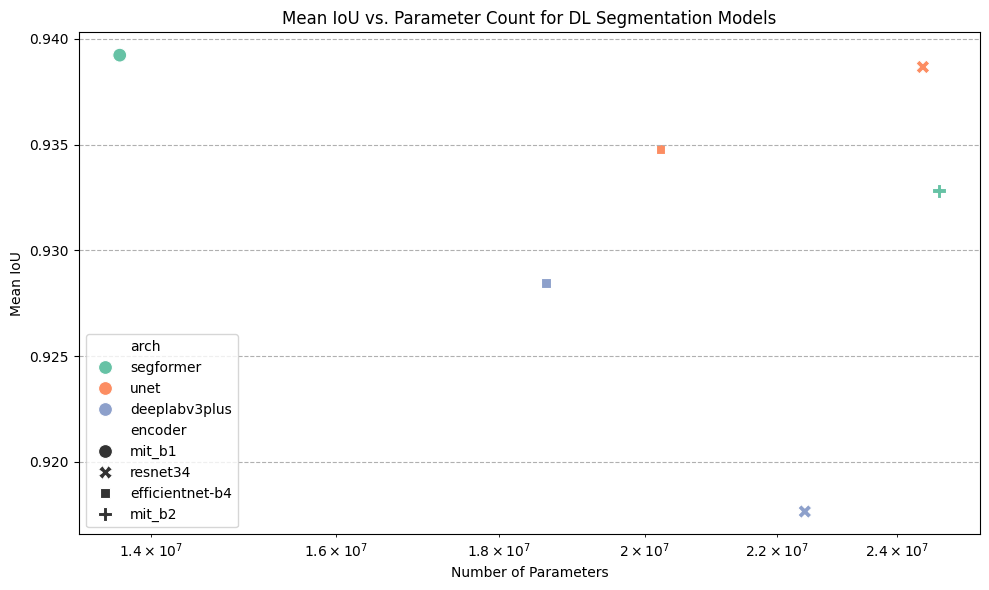

In [10]:
# Ensure results output directory
output_dir = BASE_DIR / ".." / "results"
output_dir.mkdir(parents=True, exist_ok=True)

# Plotting metrics

# Plot a scatter plot of mean IoU vs. parameter count for each model
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    x='parameters', y='iou',
    hue='arch',
    style='encoder',
    data=model_overall_metrics,
    ax=ax,
    palette='Set2',
    s=100
)
plt.title('Mean IoU vs. Parameter Count for DL Segmentation Models')
plt.xlabel('Number of Parameters')
plt.ylabel('Mean IoU')
plt.xscale('log')
plt.grid(True, axis='y', ls='--')
plt.tight_layout()

Figure saved to: ../data/../results/dl_evaluation_overview.png


/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_2754/2531704181.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


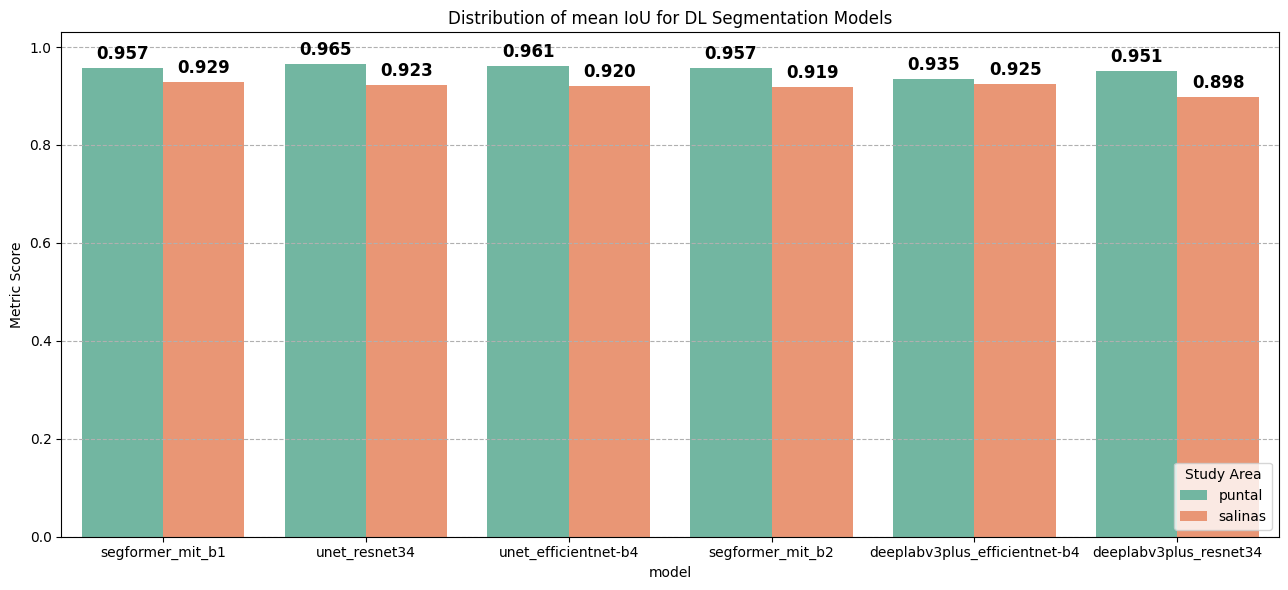

In [13]:
# Plot a bar plot of mean IoU for each model, colored by study area
# Sort df_results by model mean IoU to match overall metrics ranking
model_order = model_overall_metrics['model'].tolist()
df_results['model'] = pd.Categorical(df_results['model'], categories=model_order, ordered=True)
df_results = df_results.sort_values('model').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(
    x='model', y='iou',
    hue='study_name',
    data=df_results,
    ax=ax,
    palette='Set2',
    ci=None
    )
# Add bar labels for mean IoU values on top of bars
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.text(
            p.get_x() + p.get_width() / 2., 
            height + 0.01, 
            f'{height:.3f}', 
            ha="center", 
            va="bottom",
            fontsize=12,
            fontweight='bold'
        )
plt.title('Distribution of mean IoU for DL Segmentation Models')
plt.ylabel('Metric Score')
plt.ylim(0, 1.03)
plt.legend(title='Study Area', loc='lower right')
plt.grid(True, axis='y', ls='--')
plt.tight_layout()

# Save figure
plot_output_file = output_dir / "dl_evaluation_overview.png"
plt.savefig(plot_output_file, dpi=300, bbox_inches='tight')
print(f"Figure saved to: {plot_output_file}")

/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_2754/799981777.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


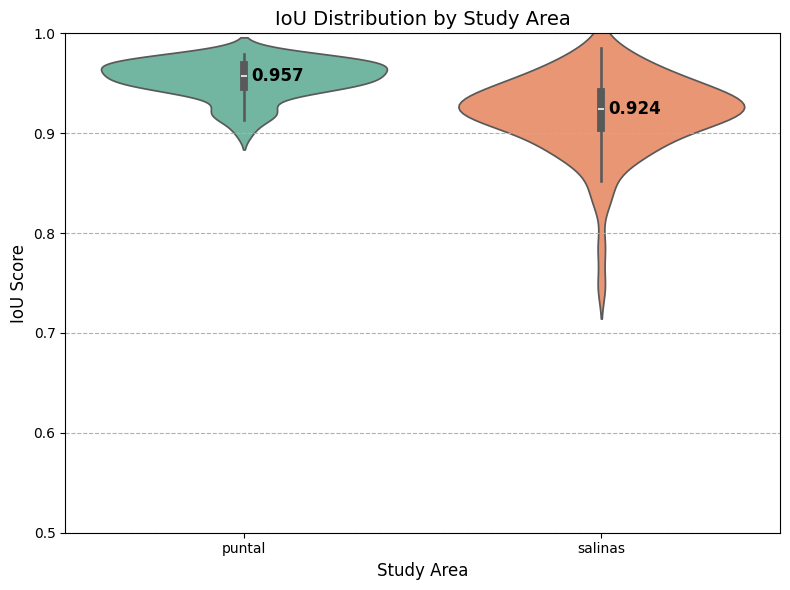

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.violinplot(
    data=df_results,
    x='study_name',
    y='iou',
    palette='Set2',
    ax=ax,
    inner='box'
)
# Add the median IoU value at the right of each violin
for i, study in enumerate(df_results['study_name'].unique()):
    median_iou = df_results[df_results['study_name'] == study]['iou'].median()
    ax.text(
        i + 0.02, 
        median_iou,
        f'{median_iou:.3f}',
        ha="left", 
        va="center",
        fontsize=12,
        fontweight='bold'
        )
ax.set_title('IoU Distribution by Study Area', fontsize=14)
ax.set_xlabel('Study Area', fontsize=12)
ax.set_ylabel('IoU Score', fontsize=12)
ax.set_ylim([0.5, 1.0])
plt.grid(True, axis='y', ls='--')
plt.tight_layout()